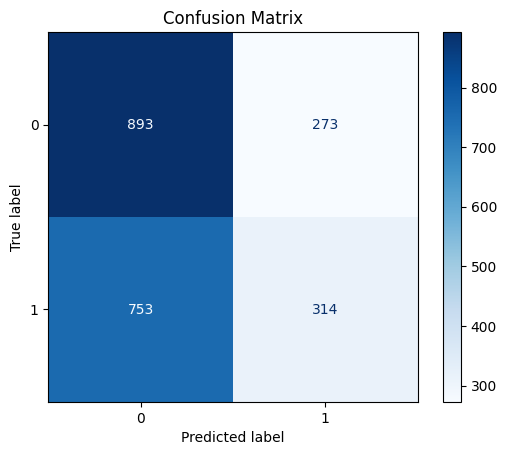

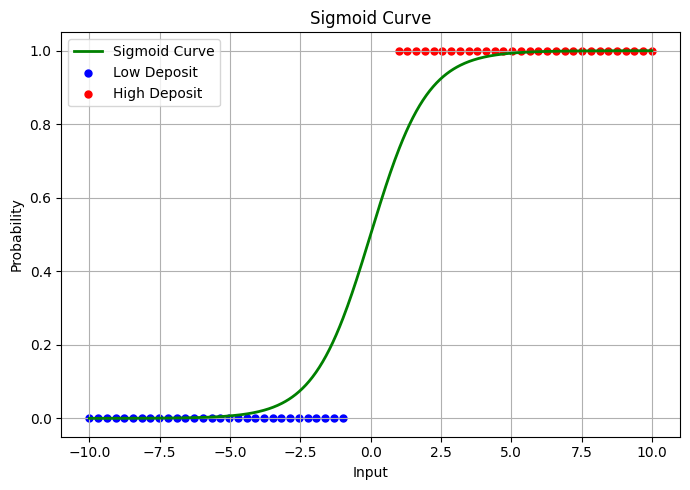

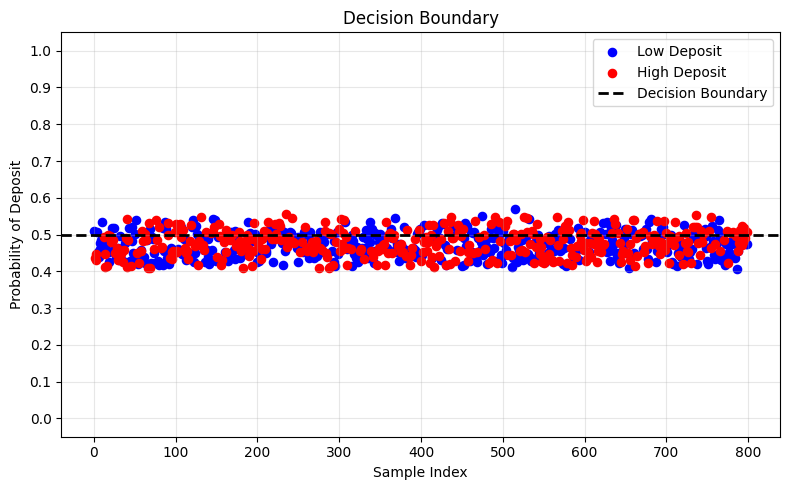

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

data = pd.read_csv("/content/bank.csv")

# ENCODE CATEGORICAL COLUMNS
encoder = LabelEncoder()
for col in data.columns:
    data[col] = encoder.fit_transform(data[col].astype(str))

# SEPARATE INPUT AND OUTPUT
X = data.drop("deposit", axis=1)
y = data["deposit"]
# Use first 2 input columns
X = X.iloc[:, :2]

# TRAIN TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.2,
random_state=42
)
# LOGISTIC REGRESSION
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# CONFUSION MATRIX
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
confusion_matrix=cm
).plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.show()

# SIGMOID CURVE

x = np.linspace(-10, 10, 500)

sigmoid = 1 / (1 + np.exp(-x))

plt.figure(figsize=(7, 5))

# Sigmoid Curve
plt.plot(
x,
sigmoid,
color="green",
linewidth=2,
label="Sigmoid Curve"
)

# Blue points = Low Deposit
blue_x = np.linspace(-10, -1, 30)

plt.scatter(
blue_x,
np.zeros(len(blue_x)),
color="blue",

s=25,
marker="o",
label="Low Deposit"
)

# Red points = High Deposit
red_x = np.linspace(1, 10, 30)

plt.scatter(
red_x,
np.ones(len(red_x)),
color="red",
s=25,
marker="o",
label="High Deposit"
)

plt.title("Sigmoid Curve")
plt.xlabel("Input")
plt.ylabel("Probability")

plt.ylim(-0.05, 1.05)

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# DECISION BOUNDARY
# Predicted probabilities
prob = model.predict_proba(X_test)[:, 1]

# Take first 800 samples
prob_small = prob[:800]
y_small = y_test.iloc[:800]

# Sample index
sample_index = np.arange(len(prob_small))

plt.figure(figsize=(8, 5))

# Low Deposit / Class 0
plt.scatter(
sample_index[y_small.values == 0],
prob_small[y_small.values == 0],
color="blue",
s=35,
label="Low Deposit"
)
# High Deposit / Class 1
plt.scatter(
sample_index[y_small.values == 1],
prob_small[y_small.values == 1],
color="red",
s=35,
label="High Deposit"
)

# Decision Boundary
plt.axhline(
y=0.5,
color="black",
linestyle="--",
linewidth=2,
label="Decision Boundary"
)

plt.xlabel("Sample Index")
plt.ylabel("Probability of Deposit")
plt.title("Decision Boundary")

plt.ylim(-0.05, 1.05)
plt.yticks(np.arange(0, 1.1, 0.1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()